In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/sample_submission.csv
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/train.csv
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test.csv
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_49.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_90.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_77.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_66.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_54.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_42.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_81.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_72.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final

In [2]:
!pip install -q faster-whisper sentence-transformers lightgbm language-tool-python

!nvidia-smi --query-gpu=name,memory.total --format=csv

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 4.5 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.2/63.2 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 59.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.6/39.6 MB 51.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 77.2 MB/s eta 0:00:00:00:0100:01
name, memory.total [MiB]
Tesla T4, 15360 MiB
Tesla T4, 15360 MiB


In [3]:
import os, re, json, glob, time, random, shutil, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm

warnings.filterwarnings("ignore")


SEED = 42

try:
    import torch

    HAS_GPU = torch.cuda.is_available()
    GPU_NAME = torch.cuda.get_device_name(0) if HAS_GPU else "none"

except Exception:
    torch, HAS_GPU, GPU_NAME = None, False, "none"


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

    if torch is not None:
        torch.manual_seed(seed)

        if HAS_GPU:
            torch.cuda.manual_seed_all(seed)


seed_everything()


DEVICE = "cuda" if HAS_GPU else "cpu"


WORK = "/kaggle/working" if os.path.exists("/kaggle/working") else "./working"

os.makedirs(WORK, exist_ok=True)




WHISPER_MODEL = "small.en"

USE_FILLER_PROMPT = False


BEAM_SIZE = 1

# Maximum transcription time per notebook session
TIME_LIMIT_MIN = 600

# Text embedding model
EMB_MODEL = "all-MiniLM-L6-v2"

# Audio embeddings later use karne hain ya nahi
USE_AUDIO_EMB = True

# Grammar checking ke liye LanguageTool
USE_LANGUAGETOOL = True

# Cross-validation folds
N_SPLITS = 5


print("Device:", DEVICE)
print("GPU:", GPU_NAME)
print("Work dir:", WORK)

Device: cuda
GPU: Tesla T4
Work dir: /kaggle/working


In [4]:
AUDIO_EXT = (".wav", ".mp3", ".flac", ".m4a", ".ogg")


def stem_of(x):
    b = os.path.basename(str(x).strip())

    for e in AUDIO_EXT:
        if b.lower().endswith(e):
            return b[:-len(e)]

    return b


# ------------------------------------------------------------
# Find folder containing train.csv and test.csv
# ------------------------------------------------------------

def find_csv_root():
    roots = []

    for r, d, f in os.walk("/kaggle/input"):
        names = [x.lower() for x in f]

        if "train.csv" in names and "test.csv" in names:
            roots.append(r)

    roots.sort(key=len)

    return roots[0] if roots else None


def pick(root, name):
    for f in os.listdir(root):
        if f.lower() == name:
            return os.path.join(root, f)

    return None


DATA_ROOT = find_csv_root()

assert DATA_ROOT, (
    "train.csv/test.csv nahi mili. "
    "Kaggle ke right panel me Add Input se dataset attach karo."
)

print("DATA_ROOT:", DATA_ROOT)


# ------------------------------------------------------------
# Load CSV files
# ------------------------------------------------------------

train_df = pd.read_csv(
    pick(DATA_ROOT, "train.csv")
)

test_df = pd.read_csv(
    pick(DATA_ROOT, "test.csv")
)

sample_sub = pd.read_csv(
    pick(DATA_ROOT, "sample_submission.csv")
)


print("Columns train:", list(train_df.columns))
print("Columns test:", list(test_df.columns))
print("Columns sample_sub:", list(sample_sub.columns))


# ------------------------------------------------------------
# Find all audio files
# ------------------------------------------------------------

AUDIO = {
    "train": {},
    "test": {},
    "all": {}
}


for r, d, f in os.walk("/kaggle/input"):

    parts = [p.lower() for p in r.split(os.sep)]

    split = (
        "train"
        if "train" in parts
        else ("test" if "test" in parts else "all")
    )

    for fn in f:

        if fn.lower().endswith(AUDIO_EXT):

            stem = stem_of(fn)

            AUDIO[split][stem] = os.path.join(r, fn)
            AUDIO["all"][stem] = os.path.join(r, fn)


print(
    "Audio files found -> "
    "train:", len(AUDIO["train"]),
    "test:", len(AUDIO["test"]),
    "other:",
    len(AUDIO["all"])
    - len(AUDIO["train"])
    - len(AUDIO["test"])
)


# ------------------------------------------------------------
# Resolve audio path
# ------------------------------------------------------------

def resolve_audio(name, split):

    s = stem_of(name)

    return (
        AUDIO[split].get(s)
        or AUDIO["all"].get(s)
    )


# ------------------------------------------------------------
# Detect filename column automatically
# ------------------------------------------------------------

def detect_file_col(df, split):

    best = None
    best_hit = -1.0

    for c in df.columns:

        hit = float(
            np.mean([
                resolve_audio(v, split) is not None
                for v in df[c].head(200)
            ])
        )

        if hit > best_hit:

            best = c
            best_hit = hit

    return best, best_hit


# ------------------------------------------------------------
# Detect label column
# ------------------------------------------------------------

def detect_label_col(df, file_col):

    cands = []

    for c in df.columns:

        if c == file_col:
            continue

        if not pd.api.types.is_numeric_dtype(df[c]):
            continue

        v = df[c].dropna()

        if len(v) and v.min() >= 0 and v.max() <= 5.5 and v.nunique() > 2:

            cands.append(c)

    for c in cands:

        if re.search(
            "label|score|grammar|mos",
            str(c),
            re.I
        ):

            return c

    return cands[0] if cands else None


# ------------------------------------------------------------
# Detect columns
# ------------------------------------------------------------

FILE_COL, hit = detect_file_col(
    train_df,
    "train"
)

assert hit > 0.9, (
    f"Filename column match weak (hit={hit:.2f}). "
    f"Columns: {list(train_df.columns)}"
)


LABEL_COL = detect_label_col(
    train_df,
    FILE_COL
)

assert LABEL_COL, (
    "Label column nahi mila. LABEL_COL manually set karo."
)


TEST_FILE_COL, hit2 = detect_file_col(
    test_df,
    "test"
)

assert hit2 > 0.9, "Test filename column match weak"


HAS_EXT = bool(
    train_df[FILE_COL]
    .astype(str)
    .str.lower()
    .str.endswith(AUDIO_EXT)
    .mean() > 0.5
)


print(
    f"FILE_COL={FILE_COL} | "
    f"LABEL_COL={LABEL_COL} | "
    f"TEST_FILE_COL={TEST_FILE_COL}"
)

print(
    "CSV me extension (.wav) likha hai:",
    HAS_EXT
)


# ------------------------------------------------------------
# Add stem + audio path
# ------------------------------------------------------------

for df, col, split in [
    (train_df, FILE_COL, "train"),
    (test_df, TEST_FILE_COL, "test")
]:

    df["stem"] = df[col].map(stem_of)

    df["path"] = [
        resolve_audio(v, split)
        for v in df[col]
    ]

    assert df["path"].notna().all(), (
        f"{split}: kuch audio files nahi mili"
    )


# Remove rows without labels
train_df = (
    train_df
    .dropna(subset=[LABEL_COL])
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Detect submission columns
# ------------------------------------------------------------

def detect_sub_cols(sub, test_stems):

    sset = set(test_stems)

    best = None
    best_hit = -1.0

    for c in sub.columns:

        h = float(
            np.mean([
                stem_of(v) in sset
                for v in sub[c].head(300)
            ])
        )

        if h > best_hit:

            best = c
            best_hit = h

    others = [
        c for c in sub.columns
        if c != best
    ]

    return (
        best,
        others[0] if others else None,
        best_hit
    )


SUB_ID_COL, SUB_LABEL_COL, SUB_ID_HIT = detect_sub_cols(
    sample_sub,
    test_df["stem"]
)


print(
    f"Submission: "
    f"id col={SUB_ID_COL} | "
    f"label col={SUB_LABEL_COL} | "
    f"id match={SUB_ID_HIT:.2f}"
)


print(
    "train rows:", len(train_df),
    "| test rows:", len(test_df),
    "| sample_sub rows:", len(sample_sub)
)


display(train_df.head(3))


DATA_ROOT: /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final
Columns train: ['filename', 'label']
Columns test: ['filename', 'label']
Columns sample_sub: ['filename', 'label']
Audio files found -> train: 769 test: 216 other: -212
FILE_COL=filename | LABEL_COL=label | TEST_FILE_COL=filename
CSV me extension (.wav) likha hai: True
Submission: id col=filename | label col=label | id match=0.12
train rows: 769 | test rows: 216 | sample_sub rows: 204


,filename,label,stem,path
0,audio_192.wav,3.0,audio_192,/kaggle/input/competitions/shl-hiring-assessme...
1,audio_436.wav,3.0,audio_436,/kaggle/input/competitions/shl-hiring-assessme...
2,audio_447.wav,3.5,audio_447,/kaggle/input/competitions/shl-hiring-assessme...


In [5]:
print("========== TEST CSV ==========")
print("Rows:", len(test_df))
print(test_df.head(10))

print("\n========== SAMPLE SUBMISSION ==========")
print("Rows:", len(sample_sub))
print(sample_sub.head(10))

print("\n========== SAMPLE SUBMISSION TAIL ==========")
print(sample_sub.tail(10))

print("\n========== TEST FILENAMES ==========")
print(test_df["filename"].head(20).tolist())

print("\n========== SAMPLE IDs ==========")
print(sample_sub["filename"].head(20).tolist())

print("\n========== ID OVERLAP ==========")

test_ids = set(
    test_df["filename"]
    .astype(str)
    .map(stem_of)
)

sub_ids = set(
    sample_sub["filename"]
    .astype(str)
    .map(stem_of)
)

print("Test unique IDs:", len(test_ids))
print("Submission unique IDs:", len(sub_ids))
print("Common IDs:", len(test_ids & sub_ids))
print("Missing from submission:", len(test_ids - sub_ids))
print("Extra in submission:", len(sub_ids - test_ids))

print("\n========== MISSING IDs ==========")
print(sorted(test_ids - sub_ids)[:30])

print("\n========== EXTRA IDs ==========")
print(sorted(sub_ids - test_ids)[:30])

========== TEST CSV ==========
Rows: 216
        filename  label       stem  \
0  audio_128.wav     -1  audio_128   
1  audio_156.wav     -1  audio_156   
2   audio_19.wav     -1   audio_19   
3  audio_108.wav     -1  audio_108   
4  audio_206.wav     -1  audio_206   
5  audio_161.wav     -1  audio_161   
6  audio_215.wav     -1  audio_215   
7  audio_213.wav     -1  audio_213   
8   audio_11.wav     -1   audio_11   
9  audio_155.wav     -1  audio_155   

                                                path  
0  /kaggle/input/competitions/shl-hiring-assessme...  
1  /kaggle/input/competitions/shl-hiring-assessme...  
2  /kaggle/input/competitions/shl-hiring-assessme...  
3  /kaggle/input/competitions/shl-hiring-assessme...  
4  /kaggle/input/competitions/shl-hiring-assessme...  
5  /kaggle/input/competitions/shl-hiring-assessme...  
6  /kaggle/input/competitions/shl-hiring-assessme...  
7  /kaggle/input/competitions/shl-hiring-assessme...  
8  /kaggle/input/competitions/shl-hiring-asse

In [6]:
print("========== DATASET ROOT ==========")
print(DATA_ROOT)

print("\n========== FILES IN DATASET ROOT ==========")

for f in os.listdir(DATA_ROOT):
    full = os.path.join(DATA_ROOT, f)

    if os.path.isfile(full):
        size_mb = os.path.getsize(full) / (1024 * 1024)
        print(f"{f:30} {size_mb:.2f} MB")


print("\n========== CSV SHAPES ==========")

for name in ["train.csv", "test.csv", "sample_submission.csv"]:
    
    path = pick(DATA_ROOT, name)
    
    if path:
        df_tmp = pd.read_csv(path)
        print(
            f"{name:25} "
            f"rows={len(df_tmp):4} "
            f"columns={list(df_tmp.columns)}"
        )


print("\n========== TRAIN ID RANGE ==========")

train_nums = (
    train_df["filename"]
    .astype(str)
    .str.extract(r"audio_(\d+)", expand=False)
    .astype(int)
)

print("min:", train_nums.min())
print("max:", train_nums.max())
print("unique:", train_nums.nunique())


print("\n========== TEST ID RANGE ==========")

test_nums = (
    test_df["filename"]
    .astype(str)
    .str.extract(r"audio_(\d+)", expand=False)
    .astype(int)
)

print("min:", test_nums.min())
print("max:", test_nums.max())
print("unique:", test_nums.nunique())


print("\n========== SAMPLE SUBMISSION ID RANGE ==========")

sub_nums = (
    sample_sub["filename"]
    .astype(str)
    .str.extract(r"audio_(\d+)", expand=False)
    .astype(int)
)

print("min:", sub_nums.min())
print("max:", sub_nums.max())
print("unique:", sub_nums.nunique())


print("\n========== FIRST/LAST TEST IDS ==========")
print(test_df["filename"].head(20).tolist())
print("...")
print(test_df["filename"].tail(20).tolist())


print("\n========== FIRST/LAST SAMPLE IDs ==========")
print(sample_sub["filename"].head(20).tolist())
print("...")
print(sample_sub["filename"].tail(20).tolist())

========== DATASET ROOT ==========
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final

========== FILES IN DATASET ROOT ==========
sample_submission.csv          0.00 MB
train.csv                      0.01 MB
test.csv                       0.00 MB

========== CSV SHAPES ==========
train.csv                 rows= 769 columns=['filename', 'label']
test.csv                  rows= 216 columns=['filename', 'label']
sample_submission.csv     rows= 204 columns=['filename', 'label']

========== TRAIN ID RANGE ==========
min: 0
max: 5073
unique: 769

========== TEST ID RANGE ==========
min: 0
max: 215
unique: 216

========== SAMPLE SUBMISSION ID RANGE ==========
min: 13
max: 1329
unique: 204

========== FIRST/LAST TEST IDS ==========
['audio_128.wav', 'audio_156.wav', 'audio_19.wav', 'audio_108.wav', 'audio_206.wav', 'audio_161.wav', 'audio_215.wav', 'audio_213.wav', 'audio_11.wav', 'audio_155.wav', 'audio_39.wav', 'audio_168.wav', 'audio_133.wav', 'audio_28.wav', 'audio_40.wav

In [7]:
# ============================================================
# FIX: Actual competition test set has 216 files
# sample_submission.csv contains stale 204 IDs
# ============================================================

print("Creating submission template from actual test.csv...")

# Use the real 216 test filenames
submission_template = test_df[["filename"]].copy()

# Placeholder predictions
submission_template["label"] = -1.0

# Submission configuration
SUB_ID_COL = "filename"
SUB_LABEL_COL = "label"

print("Submission template created.")
print("Rows:", len(submission_template))
print("Columns:", list(submission_template.columns))

print("\nFirst 5:")
display(submission_template.head())

print("\nLast 5:")
display(submission_template.tail())

print("\nExpected:")
print("Test rows       :", len(test_df))
print("Submission rows :", len(submission_template))

Creating submission template from actual test.csv...
Submission template created.
Rows: 216
Columns: ['filename', 'label']

First 5:


,filename,label
0,audio_128.wav,-1.0
1,audio_156.wav,-1.0
2,audio_19.wav,-1.0
3,audio_108.wav,-1.0
4,audio_206.wav,-1.0



Last 5:


,filename,label
211,audio_184.wav,-1.0
212,audio_24.wav,-1.0
213,audio_140.wav,-1.0
214,audio_165.wav,-1.0
215,audio_170.wav,-1.0



Expected:
Test rows       : 216
Submission rows : 216


Label statistics:
count    769.000000
mean       3.313394
std        1.239000
min        0.000000
25%        2.500000
50%        3.000000
75%        4.000000
max        5.000000
Name: label, dtype: float64

Labels outside 0-5: 0

Dummy baseline RMSE (always predict mean) = 1.2382


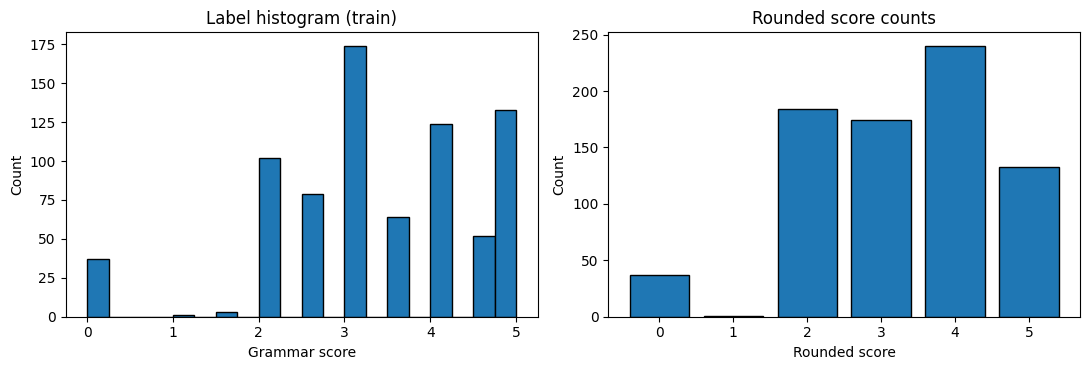

In [8]:
# ============================================================
# CELL 4: LABEL DISTRIBUTION & SANITY CHECK
# ============================================================

y = train_df[LABEL_COL].astype(float).values

print("Label statistics:")
print(train_df[LABEL_COL].describe())

print("\nLabels outside 0-5:",
      int(((y < 0) | (y > 5)).sum()))

print("\nDummy baseline RMSE (always predict mean) =",
      round(float(np.std(y)), 4))

# Plot label distribution
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))

# Histogram
ax[0].hist(y, bins=20, edgecolor="black")
ax[0].set_title("Label histogram (train)")
ax[0].set_xlabel("Grammar score")
ax[0].set_ylabel("Count")

# Rounded score counts
vc = pd.Series(np.round(y)).value_counts().sort_index()

ax[1].bar(
    vc.index.astype(int).astype(str),
    vc.values,
    edgecolor="black"
)

ax[1].set_title("Rounded score counts")
ax[1].set_xlabel("Rounded score")
ax[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

In [9]:
# ============================================================
# CELL 7: BUILD AUDIO INDEX + SMALL WHISPER TEST
# ============================================================

# Collect all WAV files
all_wavs = glob.glob(
    os.path.join(DATA_ROOT, "**", "*.wav"),
    recursive=True
)

print("Total WAV files found:", len(all_wavs))

# Create filename -> full path mapping
wav_map = {}

for p in all_wavs:
    fname = os.path.basename(p)
    wav_map[fname] = p

# Resolve train/test audio paths
train_df["audio_path"] = train_df[FILE_COL].astype(str).map(wav_map)
test_df["audio_path"] = test_df[TEST_FILE_COL].astype(str).map(wav_map)

print("Train audio paths found:",
      train_df["audio_path"].notna().sum(), "/", len(train_df))

print("Test audio paths found:",
      test_df["audio_path"].notna().sum(), "/", len(test_df))

# Show missing files if any
missing_train = train_df[train_df["audio_path"].isna()]
missing_test = test_df[test_df["audio_path"].isna()]

print("\nMissing train files:", len(missing_train))
print("Missing test files:", len(missing_test))

if len(missing_train) > 0:
    print("\nExample missing train files:")
    display(missing_train[[FILE_COL]].head())

if len(missing_test) > 0:
    print("\nExample missing test files:")
    display(missing_test[[TEST_FILE_COL]].head())

Total WAV files found: 985
Train audio paths found: 769 / 769
Test audio paths found: 216 / 216

Missing train files: 0
Missing test files: 0


In [10]:
# ============================================================
# CELL 8: WHISPER SMALL TEST
# ============================================================

from faster_whisper import WhisperModel

print("Loading Whisper model...")

whisper_model = WhisperModel(
    WHISPER_MODEL,
    device=DEVICE,
    compute_type="float16" if DEVICE == "cuda" else "int8"
)

print("Whisper model loaded successfully!")
print("Model:", WHISPER_MODEL)
print("Device:", DEVICE)

# Test on 3 training audios
sample_audio_paths = train_df["audio_path"].dropna().head(3).tolist()

print("\nTesting transcription on", len(sample_audio_paths), "audio files...\n")

for i, audio_path in enumerate(sample_audio_paths, 1):

    print("=" * 70)
    print(f"Audio {i}: {os.path.basename(audio_path)}")

    start_time = time.time()

    segments, info = whisper_model.transcribe(
        audio_path,
        beam_size=BEAM_SIZE,
        language="en"
    )

    # Convert generator to text
    text = " ".join(
        segment.text.strip()
        for segment in segments
    ).strip()

    elapsed = time.time() - start_time

    print("Detected language:", info.language)
    print("Transcript:")
    print(text)
    print(f"Time taken: {elapsed:.2f} sec")

print("=" * 70)
print("\nWhisper test completed.")

Loading Whisper model...


Whisper model loaded successfully!
Model: small.en
Device: cuda

Testing transcription on 3 audio files...

Audio 1: audio_192.wav


TypeError: open() got an unexpected keyword argument 'metadata_errors'

In [11]:
# ============================================================
# DIAGNOSTIC: CHECK AUDIO + PYAV
# ============================================================

import os
import av

test_audio = train_df["audio_path"].dropna().iloc[0]

print("Audio path:")
print(test_audio)

print("\nPath exists:", os.path.exists(test_audio))
print("Path type:", type(test_audio))

if os.path.exists(test_audio):
    print("File size (MB):",
          round(os.path.getsize(test_audio) / (1024 * 1024), 3))

print("\nPyAV version:", av.__version__)

# Try opening the audio directly
try:
    container = av.open(test_audio)
    print("\n✅ PyAV successfully opened the audio!")

    stream = container.streams.audio[0]
    print("Audio stream:", stream)

    container.close()

except Exception as e:
    print("\n❌ PyAV AUDIO ERROR")
    print("Error type:", type(e).__name__)
    print("Error message:", str(e))
    

Audio path:
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/train/audio_192.wav

Path exists: True
Path type: <class 'str'>
File size (MB): 1.847

PyAV version: 19.0.1

✅ PyAV successfully opened the audio!
Audio stream: <av.AudioStream #0 pcm_s16le at 16000Hz, 1 channels, s16 at 0x7a012c2c7880>


In [12]:
# ============================================================
# CELL 8B: WHISPER TEST - DECODE AUDIO MANUALLY
# ============================================================

import av
import numpy as np

def load_audio_with_pyav(audio_path, target_sr=16000):
    """
    Load WAV audio using PyAV and convert it to
    mono float32 NumPy array at 16 kHz.
    """

    container = av.open(audio_path)

    stream = container.streams.audio[0]

    # Decode audio frames
    frames = []

    for frame in container.decode(stream):
        audio = frame.to_ndarray()

        # Convert to mono if necessary
        if audio.ndim > 1:
            audio = audio.mean(axis=0)

        frames.append(audio)

    container.close()

    if not frames:
        raise RuntimeError("No audio frames found!")

    audio = np.concatenate(frames).astype(np.float32)

    # Normalize int16 -> [-1, 1]
    if np.max(np.abs(audio)) > 1.5:
        audio = audio / 32768.0

    return audio


# ------------------------------------------------------------
# Test on 1 audio first
# ------------------------------------------------------------

test_audio = train_df["audio_path"].dropna().iloc[0]

print("Testing:", os.path.basename(test_audio))

start_time = time.time()

try:
    audio_array = load_audio_with_pyav(test_audio)

    print("✅ Audio decoded successfully!")
    print("Samples:", len(audio_array))
    print("Duration:",
          round(len(audio_array) / 16000, 2),
          "seconds")
    print("Data type:", audio_array.dtype)

except Exception as e:
    print("❌ Audio decoding failed")
    print("Error:", type(e).__name__, str(e))
    raise


# ------------------------------------------------------------
# Whisper transcription
# ------------------------------------------------------------

print("\nRunning Whisper...")

segments, info = whisper_model.transcribe(
    audio_array,
    beam_size=BEAM_SIZE,
    language="en"
)

text = " ".join(
    segment.text.strip()
    for segment in segments
).strip()

elapsed = time.time() - start_time

print("\n" + "=" * 70)
print("TRANSCRIPTION RESULT")
print("=" * 70)

print("File:", os.path.basename(test_audio))
print("Language:", info.language)
print("Transcript:")
print(text)
print(f"\nTotal time: {elapsed:.2f} sec")

print("=" * 70)

Testing: audio_192.wav
✅ Audio decoded successfully!
Samples: 968134
Duration: 60.51 seconds
Data type: float32

Running Whisper...

TRANSCRIPTION RESULT
File: audio_192.wav
Language: en
Transcript:
The playground is very, very beautiful and fun. There are, there are playthings like the merry-go-round, the swing. The students usually enjoy this swing. It has to be like, it's more like a gimbal's pair. Once it's finished and the other person will have to finish, then the merry-go-round will just climb on it. And then most of them play for the fall. On sand parks, while others use the swing, some of the kids like to build sand castles and most times you hear the sound of screaming children laughing kids.

Total time: 1.25 sec


In [13]:
# ============================================================
# CELL 9: WHISPER VALIDATION ON 20 TRAIN + 5 TEST
# ============================================================

def transcribe_audio_array(audio_path):
    """
    Decode audio with PyAV and transcribe using Whisper.
    """

    audio = load_audio_with_pyav(audio_path)

    segments, info = whisper_model.transcribe(
        audio,
        beam_size=BEAM_SIZE,
        language="en"
    )

    text = " ".join(
        segment.text.strip()
        for segment in segments
    ).strip()

    return text, info.language


# ------------------------------------------------------------
# Select small validation samples
# ------------------------------------------------------------

train_sample = train_df.dropna(
    subset=["audio_path"]
).head(20).copy()

test_sample = test_df.dropna(
    subset=["audio_path"]
).head(5).copy()

print("Train validation audios:", len(train_sample))
print("Test validation audios :", len(test_sample))


# ------------------------------------------------------------
# Transcribe TRAIN
# ------------------------------------------------------------

train_texts = []

start_all = time.time()

print("\nTranscribing TRAIN samples...\n")

for idx, row in tqdm(
    train_sample.iterrows(),
    total=len(train_sample)
):

    try:
        text, language = transcribe_audio_array(
            row["audio_path"]
        )

        train_texts.append(text)

    except Exception as e:

        print(
            f"\n❌ Error: {row[FILE_COL]}"
        )
        print(
            type(e).__name__,
            str(e)
        )

        train_texts.append("")


# ------------------------------------------------------------
# Transcribe TEST
# ------------------------------------------------------------

test_texts = []

print("\nTranscribing TEST samples...\n")

for idx, row in tqdm(
    test_sample.iterrows(),
    total=len(test_sample)
):

    try:
        text, language = transcribe_audio_array(
            row["audio_path"]
        )

        test_texts.append(text)

    except Exception as e:

        print(
            f"\n❌ Error: {row[TEST_FILE_COL]}"
        )
        print(
            type(e).__name__,
            str(e)
        )

        test_texts.append("")


elapsed_all = time.time() - start_all


# ------------------------------------------------------------
# Store results
# ------------------------------------------------------------

train_sample["transcript"] = train_texts
test_sample["transcript"] = test_texts


print("\n" + "=" * 70)
print("WHISPER VALIDATION COMPLETE")
print("=" * 70)

print(
    f"Total processing time: {elapsed_all:.2f} sec"
)

print(
    "Train successful:",
    sum(bool(x.strip()) for x in train_texts),
    "/",
    len(train_texts)
)

print(
    "Test successful:",
    sum(bool(x.strip()) for x in test_texts),
    "/",
    len(test_texts)
)


# ------------------------------------------------------------
# Show examples
# ------------------------------------------------------------

print("\nTRAIN TRANSCRIPT EXAMPLES")
print("=" * 70)

for i in range(min(5, len(train_sample))):

    print(
        f"\n{i+1}. {train_sample.iloc[i][FILE_COL]}"
    )

    print(
        train_sample.iloc[i]["transcript"]
    )


print("\n\nTEST TRANSCRIPT EXAMPLES")
print("=" * 70)

for i in range(min(5, len(test_sample))):

    print(
        f"\n{i+1}. {test_sample.iloc[i][TEST_FILE_COL]}"
    )

    print(
        test_sample.iloc[i]["transcript"]
    )

Train validation audios: 20
Test validation audios : 5

Transcribing TRAIN samples...



  0%|          | 0/20 [00:00<?, ?it/s]


Transcribing TEST samples...



  0%|          | 0/5 [00:00<?, ?it/s]


WHISPER VALIDATION COMPLETE
Total processing time: 24.72 sec
Train successful: 20 / 20
Test successful: 5 / 5

TRAIN TRANSCRIPT EXAMPLES

1. audio_192.wav
The playground is very, very beautiful and fun. There are, there are playthings like the merry-go-round, the swing. The students usually enjoy this swing. It has to be like, it's more like a gimbal's pair. Once it's finished and the other person will have to finish, then the merry-go-round will just climb on it. And then most of them play for the fall. On sand parks, while others use the swing, some of the kids like to build sand castles and most times you hear the sound of screaming children laughing kids.

2. audio_436.wav
The scene of a school playground, our playground looks like a very big playground having a more and more greenery trees in which way students like to garden a more trees to have a fresh air and all having a fresh oxygen. This in the playground, these trees gives a very greenery view which will be very pleasant t

In [14]:
# ============================================================
# CELL 10: FULL WHISPER TRANSCRIPTION
# 769 TRAIN + 216 TEST = 985 AUDIO FILES
# ============================================================

import os
import time
import pandas as pd
from tqdm.auto import tqdm

TRAIN_TRANSCRIPT_FILE = os.path.join(
    WORK, "train_transcripts.csv"
)

TEST_TRANSCRIPT_FILE = os.path.join(
    WORK, "test_transcripts.csv"
)


def transcribe_one_audio(audio_path):
    """
    Decode audio with PyAV and transcribe using Whisper.
    """
    
    audio = load_audio_with_pyav(audio_path)

    segments, info = whisper_model.transcribe(
        audio,
        beam_size=BEAM_SIZE,
        language="en"
    )

    text = " ".join(
        segment.text.strip()
        for segment in segments
    ).strip()

    return text


# ============================================================
# TRAIN TRANSCRIPTION
# ============================================================

print("=" * 70)
print("STARTING TRAIN TRANSCRIPTION")
print("=" * 70)

train_transcripts = []

train_start = time.time()

for _, row in tqdm(
    train_df.iterrows(),
    total=len(train_df),
    desc="TRAIN"
):
    
    try:
        text = transcribe_one_audio(
            row["audio_path"]
        )
        
    except Exception as e:
        print(
            f"\n❌ Error in {row[FILE_COL]}:"
        )
        print(
            type(e).__name__,
            str(e)
        )
        text = ""

    train_transcripts.append(text)


train_result = train_df[
    [FILE_COL, LABEL_COL]
].copy()

train_result["transcript"] = train_transcripts

train_result.to_csv(
    TRAIN_TRANSCRIPT_FILE,
    index=False
)

train_time = time.time() - train_start

print("\nTRAIN TRANSCRIPTION COMPLETE")
print("Files:", len(train_result))
print("Time:", round(train_time / 60, 2), "minutes")
print(
    "Successful:",
    sum(bool(x.strip()) for x in train_transcripts),
    "/",
    len(train_transcripts)
)


# ============================================================
# TEST TRANSCRIPTION
# ============================================================

print("\n" + "=" * 70)
print("STARTING TEST TRANSCRIPTION")
print("=" * 70)

test_transcripts = []

test_start = time.time()

for _, row in tqdm(
    test_df.iterrows(),
    total=len(test_df),
    desc="TEST"
):
    
    try:
        text = transcribe_one_audio(
            row["audio_path"]
        )
        
    except Exception as e:
        print(
            f"\n❌ Error in {row[TEST_FILE_COL]}:"
        )
        print(
            type(e).__name__,
            str(e)
        )
        text = ""

    test_transcripts.append(text)


test_result = test_df[
    [TEST_FILE_COL]
].copy()

test_result["transcript"] = test_transcripts

test_result.to_csv(
    TEST_TRANSCRIPT_FILE,
    index=False
)

test_time = time.time() - test_start

print("\nTEST TRANSCRIPTION COMPLETE")
print("Files:", len(test_result))
print("Time:", round(test_time / 60, 2), "minutes")
print(
    "Successful:",
    sum(bool(x.strip()) for x in test_transcripts),
    "/",
    len(test_transcripts)
)


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("FULL TRANSCRIPTION COMPLETE")
print("=" * 70)

print(
    "Train transcripts:",
    TRAIN_TRANSCRIPT_FILE
)

print(
    "Test transcripts :",
    TEST_TRANSCRIPT_FILE
)

print(
    "\nTrain successful:",
    sum(bool(x.strip()) for x in train_transcripts),
    "/ 769"
)

print(
    "Test successful :",
    sum(bool(x.strip()) for x in test_transcripts),
    "/ 216"
)

print("\nExample TRAIN:")
display(train_result.head())

print("\nExample TEST:")
display(test_result.head())

STARTING TRAIN TRANSCRIPTION


TRAIN:   0%|          | 0/769 [00:00<?, ?it/s]


TRAIN TRANSCRIPTION COMPLETE
Files: 769
Time: 9.87 minutes
Successful: 766 / 769

STARTING TEST TRANSCRIPTION


TEST:   0%|          | 0/216 [00:00<?, ?it/s]


TEST TRANSCRIPTION COMPLETE
Files: 216
Time: 2.38 minutes
Successful: 216 / 216

FULL TRANSCRIPTION COMPLETE
Train transcripts: /kaggle/working/train_transcripts.csv
Test transcripts : /kaggle/working/test_transcripts.csv

Train successful: 766 / 769
Test successful : 216 / 216

Example TRAIN:


,filename,label,transcript
0,audio_192.wav,3.0,"The playground is very, very beautiful and fun..."
1,audio_436.wav,3.0,"The scene of a school playground, our playgrou..."
2,audio_447.wav,3.5,My favorite place to visit is the beach. I lov...
3,audio_126.wav,2.0,Once upon a time we with 5 friends went on a t...
4,audio_61.wav,2.0,"Well, when I was a child, I remember I went to..."



Example TEST:


,filename,transcript
0,audio_128.wav,Staying at a resort is a relaxing and enjoyabl...
1,audio_156.wav,"Life is full of events, both good and bad. Som..."
2,audio_19.wav,I went to Santa in Guatemala and I enjoyed thi...
3,audio_108.wav,As a young child one of the most exacting plac...
4,audio_206.wav,The best day of my life would definitely be wh...


In [15]:
# ============================================================
# CELL 10B: FIND AND RETRY FAILED TRAIN TRANSCRIPTS
# ============================================================

# Load the saved train transcripts
train_result = pd.read_csv(TRAIN_TRANSCRIPT_FILE)

# Find empty/missing transcripts
failed_mask = (
    train_result["transcript"].isna()
    | (train_result["transcript"].astype(str).str.strip() == "")
)

failed_train = train_result[failed_mask].copy()

print("Failed train transcripts:", len(failed_train))

if len(failed_train) > 0:

    print("\nFailed files:")
    display(failed_train[[FILE_COL, LABEL_COL]])

    print("\nRetrying failed files...\n")

    retry_success = 0

    for idx in failed_train.index:

        filename = train_result.loc[idx, FILE_COL]

        # Get original audio path
        audio_path = wav_map.get(str(filename))

        print("=" * 70)
        print("Retry:", filename)

        try:

            text = transcribe_one_audio(audio_path)

            train_result.loc[idx, "transcript"] = text

            if text.strip():
                retry_success += 1
                print("✅ Retry successful")
                print("Transcript:", text[:300])
            else:
                print("⚠️ Still empty")

        except Exception as e:

            print("❌ Retry failed")
            print("Error:", type(e).__name__, str(e))


    # Save updated transcripts
    train_result.to_csv(
        TRAIN_TRANSCRIPT_FILE,
        index=False
    )

    print("\n" + "=" * 70)
    print("RETRY COMPLETE")
    print("=" * 70)

    print("Recovered:", retry_success)
    print("Previously failed:", len(failed_train))

else:

    print("✅ No failed transcripts found!")


# ============================================================
# FINAL CHECK
# ============================================================

remaining_failed = (
    train_result["transcript"].isna()
    | (train_result["transcript"].astype(str).str.strip() == "")
)

print("\nFinal train transcript status:")
print(
    "Successful:",
    (~remaining_failed).sum(),
    "/",
    len(train_result)
)

print(
    "Remaining failed:",
    remaining_failed.sum()
)

Failed train transcripts: 3

Failed files:


,filename,label
41,audio_5069.wav,0.0
73,audio_5056.wav,0.0
458,audio_5049.wav,0.0



Retrying failed files...

Retry: audio_5069.wav
⚠️ Still empty
Retry: audio_5056.wav
⚠️ Still empty
Retry: audio_5049.wav
⚠️ Still empty

RETRY COMPLETE
Recovered: 0
Previously failed: 3

Final train transcript status:
Successful: 766 / 769
Remaining failed: 3


In [16]:
# ============================================================
# CELL 10C: DIAGNOSE THE 3 FAILED AUDIO FILES
# ============================================================

failed_files = [
    "audio_5069.wav",
    "audio_5056.wav",
    
    "audio_5049.wav"
]

print("=" * 70)
print("DIAGNOSING FAILED AUDIO FILES")
print("=" * 70)

for filename in failed_files:

    audio_path = wav_map[filename]

    print("\n" + "-" * 70)
    print("File:", filename)
    print("Path:", audio_path)

    try:
        # Load audio
        audio = load_audio_with_pyav(audio_path)

        duration = len(audio) / 16000
        max_amplitude = float(np.max(np.abs(audio)))
        mean_amplitude = float(np.mean(np.abs(audio)))
        rms = float(np.sqrt(np.mean(audio ** 2)))

        print("Duration       :", round(duration, 2), "seconds")
        print("Samples        :", len(audio))
        print("Max amplitude  :", round(max_amplitude, 6))
        print("Mean amplitude :", round(mean_amplitude, 6))
        print("RMS            :", round(rms, 6))

        # Basic silence check
        if max_amplitude < 0.001:
            print("⚠️ VERY LOW / SILENT AUDIO")
        elif rms < 0.005:
            print("⚠️ VERY LOW AUDIO SIGNAL")
        else:
            print("✅ Audio signal is present")

    except Exception as e:

        print("❌ Could not analyze audio")
        print("Error:", type(e).__name__, str(e))
        

DIAGNOSING FAILED AUDIO FILES

----------------------------------------------------------------------
File: audio_5069.wav
Path: /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/train/audio_5069.wav
Duration       : 60.07 seconds
Samples        : 961195
Max amplitude  : 0.950012
Mean amplitude : 0.089456
RMS            : 0.114312
✅ Audio signal is present

----------------------------------------------------------------------
File: audio_5056.wav
Path: /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/train/audio_5056.wav
Duration       : 60.08 seconds
Samples        : 961280
Max amplitude  : 0.950012
Mean amplitude : 0.07559
RMS            : 0.096729
✅ Audio signal is present

----------------------------------------------------------------------
File: audio_5049.wav
Path: /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/train/audio_5049.wav
Duration       : 60.07 seconds
Samples        : 961195
Max amplitude  : 0.950012
Mean amp

In [17]:
# ============================================================
# CELL 10D: SPECIAL WHISPER RETRY FOR 3 FAILED FILES
# ============================================================

failed_files = [
    "audio_5069.wav",
    "audio_5056.wav",
    "audio_5049.wav"
]

print("=" * 70)
print("SPECIAL WHISPER RETRY")
print("=" * 70)

for filename in failed_files:

    audio_path = wav_map[filename]

    print("\n" + "-" * 70)
    print("File:", filename)

    try:
        # Load audio
        audio = load_audio_with_pyav(audio_path)

        # Whisper with relaxed decoding settings
        segments, info = whisper_model.transcribe(
            audio,
            language="en",
            task="transcribe",
            beam_size=5,
            best_of=5,
            temperature=0.0,
            vad_filter=False,
            condition_on_previous_text=False,
            no_speech_threshold=0.9,
            log_prob_threshold=-1.0,
            compression_ratio_threshold=3.0
        )

        # IMPORTANT:
        # segments is a generator, so consume it here
        segments_list = list(segments)

        text = " ".join(
            segment.text.strip()
            for segment in segments_list
        ).strip()

        print("Detected language:", info.language)
        print("Number of segments:", len(segments_list))

        if text:
            print("✅ TRANSCRIPT FOUND")
            print(text)

            # Update saved train dataframe
            mask = train_result[FILE_COL].astype(str) == filename

            train_result.loc[
                mask,
                "transcript"
            ] = text

        else:
            print("⚠️ Still no transcript returned.")

    except Exception as e:

        print("❌ Whisper retry failed")
        print("Error type:", type(e).__name__)
        print("Error:", str(e))


# Save updated dataframe
train_result.to_csv(
    TRAIN_TRANSCRIPT_FILE,
    index=False
)


# ============================================================
# FINAL STATUS
# ============================================================

remaining_failed = (
    train_result["transcript"].isna()
    | (train_result["transcript"].astype(str).str.strip() == "")
)

print("\n" + "=" * 70)
print("FINAL STATUS")
print("=" * 70)

print(
    "Successful:",
    (~remaining_failed).sum(),
    "/",
    len(train_result)
)

print(
    "Remaining failed:",
    remaining_failed.sum()
)

if remaining_failed.sum() > 0:
    print("\nStill failed:")
    display(
        train_result.loc[
            remaining_failed,
            [FILE_COL, LABEL_COL]
        ]
    )

SPECIAL WHISPER RETRY

----------------------------------------------------------------------
File: audio_5069.wav
Detected language: en
Number of segments: 23
✅ TRANSCRIPT FOUND
The third part is that it is in a certain level. Not a certain place. Not a certain place. It's in a particular product. It's in a particular product. It's in a particular product. It's in a particular product. It's in a particular product. I don't know how to do it. I can do it just by confusing me. I don't know how to do it. I don't know how to do it. I don't know how to do it. I don't know how to do it. I don't know how to do it. I don't know how to do it. I don't know how to do it. I don't know how to do it. I don't know how to do it. I don't know how to do it. I don't know how to do it. I don't know how to do it. to learn a little bit about this project.

----------------------------------------------------------------------
File: audio_5056.wav
Detected language: en
Number of segments: 5
✅ TRANSCRIPT FOU

In [18]:
# ============================================================
# CELL 11: FINAL TRANSCRIPT VERIFICATION
# ============================================================

# Reload saved files
train_transcripts_df = pd.read_csv(TRAIN_TRANSCRIPT_FILE)
test_transcripts_df = pd.read_csv(TEST_TRANSCRIPT_FILE)

print("=" * 70)
print("TRANSCRIPT VERIFICATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. ROW COUNTS
# ------------------------------------------------------------

print("\n1. ROW COUNTS")

print(
    "Train:",
    len(train_transcripts_df),
    "| Expected:",
    len(train_df)
)

print(
    "Test :",
    len(test_transcripts_df),
    "| Expected:",
    len(test_df)
)


# ------------------------------------------------------------
# 2. MISSING / EMPTY TRANSCRIPTS
# ------------------------------------------------------------

train_empty = (
    train_transcripts_df["transcript"].isna()
    | (
        train_transcripts_df["transcript"]
        .fillna("")
        .astype(str)
        .str.strip() == ""
    )
)

test_empty = (
    test_transcripts_df["transcript"].isna()
    | (
        test_transcripts_df["transcript"]
        .fillna("")
        .astype(str)
        .str.strip() == ""
    )
)

print("\n2. EMPTY TRANSCRIPTS")

print(
    "Train empty:",
    int(train_empty.sum())
)

print(
    "Test empty :",
    int(test_empty.sum())
)


# ------------------------------------------------------------
# 3. FILENAME ALIGNMENT
# ------------------------------------------------------------

train_alignment = (
    train_transcripts_df[FILE_COL]
    .astype(str)
    .reset_index(drop=True)
    .equals(
        train_df[FILE_COL]
        .astype(str)
        .reset_index(drop=True)
    )
)

test_alignment = (
    test_transcripts_df[TEST_FILE_COL]
    .astype(str)
    .reset_index(drop=True)
    .equals(
        test_df[TEST_FILE_COL]
        .astype(str)
        .reset_index(drop=True)
    )
)

print("\n3. FILENAME ALIGNMENT")

print(
    "Train alignment:",
    train_alignment
)

print(
    "Test alignment :",
    test_alignment
)


# ------------------------------------------------------------
# 4. DUPLICATE FILENAMES
# ------------------------------------------------------------

print("\n4. DUPLICATE FILENAMES")

print(
    "Train duplicates:",
    train_transcripts_df[FILE_COL].duplicated().sum()
)

print(
    "Test duplicates :",
    test_transcripts_df[TEST_FILE_COL].duplicated().sum()
)


# ------------------------------------------------------------
# 5. TRANSCRIPT LENGTH
# ------------------------------------------------------------

train_lengths = (
    train_transcripts_df["transcript"]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

test_lengths = (
    test_transcripts_df["transcript"]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

print("\n5. WORD COUNT STATISTICS")

print("\nTRAIN:")
print(train_lengths.describe().round(2))

print("\nTEST:")
print(test_lengths.describe().round(2))


# ------------------------------------------------------------
# FINAL CHECK
# ------------------------------------------------------------

all_good = (
    len(train_transcripts_df) == 769
    and len(test_transcripts_df) == 216
    and train_empty.sum() == 0
    and test_empty.sum() == 0
    and train_alignment
    and test_alignment
    and train_transcripts_df[FILE_COL].duplicated().sum() == 0
    and test_transcripts_df[TEST_FILE_COL].duplicated().sum() == 0
)

print("\n" + "=" * 70)

if all_good:
    print("✅ ALL CHECKS PASSED")
    print("Dataset is ready for feature extraction!")
else:
    print("⚠️ SOME CHECKS FAILED")

print("=" * 70)

TRANSCRIPT VERIFICATION

1. ROW COUNTS
Train: 769 | Expected: 769
Test : 216 | Expected: 216

2. EMPTY TRANSCRIPTS
Train empty: 0
Test empty : 0

3. FILENAME ALIGNMENT
Train alignment: True
Test alignment : True

4. DUPLICATE FILENAMES
Train duplicates: 0
Test duplicates : 0

5. WORD COUNT STATISTICS

TRAIN:
count    769.00
mean      98.42
std       27.22
min        1.00
25%       80.00
50%       99.00
75%      119.00
max      153.00
Name: transcript, dtype: float64

TEST:
count    216.00
mean      94.17
std       22.75
min       37.00
25%       79.00
50%       91.50
75%      108.25
max      148.00
Name: transcript, dtype: float64

✅ ALL CHECKS PASSED
Dataset is ready for feature extraction!


In [19]:
# ============================================================
# CELL 12: HANDCRAFTED GRAMMAR / TEXT FEATURES
# ============================================================

import re
import numpy as np
import pandas as pd


def extract_text_features(text):
    """
    Extract simple grammar/text features from transcript.
    """

    if not isinstance(text, str):
        text = ""

    text = text.strip()

    # --------------------------------------------------------
    # Basic tokens
    # --------------------------------------------------------

    words = re.findall(r"\b[\w']+\b", text.lower())

    word_count = len(words)

    unique_words = len(set(words))

    unique_word_ratio = (
        unique_words / word_count
        if word_count > 0 else 0.0
    )

    # --------------------------------------------------------
    # Sentences
    # --------------------------------------------------------

    sentences = [
        s.strip()
        for s in re.split(r"[.!?]+", text)
        if s.strip()
    ]

    sentence_count = len(sentences)

    avg_sentence_length = (
        word_count / sentence_count
        if sentence_count > 0 else word_count
    )

    # --------------------------------------------------------
    # Long words
    # --------------------------------------------------------

    long_words = sum(
        len(w) >= 7
        for w in words
    )

    long_word_ratio = (
        long_words / word_count
        if word_count > 0 else 0.0
    )

    # --------------------------------------------------------
    # Repetition
    # --------------------------------------------------------

    repeated_words = (
        word_count - unique_words
    )

    repetition_ratio = (
        repeated_words / word_count
        if word_count > 0 else 0.0
    )

    # --------------------------------------------------------
    # Filler words
    # --------------------------------------------------------

    filler_words = {
        "um",
        "uh",
        "hmm",
        "erm",
        "like",
        "you know",
        "actually",
        "basically",
        "so"
    }

    filler_count = sum(
        1
        for w in words
        if w in filler_words
    )

    filler_ratio = (
        filler_count / word_count
        if word_count > 0 else 0.0
    )

    # --------------------------------------------------------
    # Function words
    # --------------------------------------------------------

    function_words = {
        "the", "a", "an",
        "is", "am", "are",
        "was", "were",
        "be", "been", "being",
        "have", "has", "had",
        "do", "does", "did",
        "will", "would",
        "can", "could",
        "should",
        "may", "might",
        "must",
        "to", "of", "in",
        "on", "at", "for",
        "with", "from",
        "by", "about",
        "and", "or", "but",
        "if", "because",
        "as", "than"
    }

    function_word_count = sum(
        1
        for w in words
        if w in function_words
    )

    function_word_ratio = (
        function_word_count / word_count
        if word_count > 0 else 0.0
    )

    # --------------------------------------------------------
    # Punctuation
    # --------------------------------------------------------

    punctuation_count = len(
        re.findall(r"[,.!?;:]", text)
    )

    punctuation_ratio = (
        punctuation_count / word_count
        if word_count > 0 else 0.0
    )

    # --------------------------------------------------------
    # Feature dictionary
    # --------------------------------------------------------

    return {
        "word_count": word_count,
        "unique_words": unique_words,
        "unique_word_ratio": unique_word_ratio,
        "sentence_count": sentence_count,
        "avg_sentence_length": avg_sentence_length,
        "long_words": long_words,
        "long_word_ratio": long_word_ratio,
        "repeated_words": repeated_words,
        "repetition_ratio": repetition_ratio,
        "filler_count": filler_count,
        "filler_ratio": filler_ratio,
        "function_word_count": function_word_count,
        "function_word_ratio": function_word_ratio,
        "punctuation_count": punctuation_count,
        "punctuation_ratio": punctuation_ratio
    }


# ============================================================
# APPLY TO TRAIN + TEST
# ============================================================

train_feature_rows = [
    extract_text_features(text)
    for text in train_transcripts_df["transcript"]
]

test_feature_rows = [
    extract_text_features(text)
    for text in test_transcripts_df["transcript"]
]


train_features = pd.DataFrame(train_feature_rows)

test_features = pd.DataFrame(test_feature_rows)


# Add filename + label
train_features.insert(
    0,
    FILE_COL,
    train_transcripts_df[FILE_COL].values
)

train_features["label"] = train_transcripts_df[LABEL_COL].values

test_features.insert(
    0,
    TEST_FILE_COL,
    test_transcripts_df[TEST_FILE_COL].values
)


# ============================================================
# DISPLAY RESULTS
# ============================================================

print("=" * 70)
print("HANDCRAFTED FEATURES CREATED")
print("=" * 70)

print("\nTrain shape:", train_features.shape)
print("Test shape :", test_features.shape)

print("\nFeature columns:")

for col in train_features.columns:
    print(" -", col)

print("\nTRAIN FEATURE SAMPLE:")
display(train_features.head())

print("\nFEATURE STATISTICS:")
display(
    train_features.drop(
        columns=[FILE_COL, "label"]
    ).describe().round(3)
)

HANDCRAFTED FEATURES CREATED

Train shape: (769, 17)
Test shape : (216, 16)

Feature columns:
 - filename
 - word_count
 - unique_words
 - unique_word_ratio
 - sentence_count
 - avg_sentence_length
 - long_words
 - long_word_ratio
 - repeated_words
 - repetition_ratio
 - filler_count
 - filler_ratio
 - function_word_count
 - function_word_ratio
 - punctuation_count
 - punctuation_ratio
 - label

TRAIN FEATURE SAMPLE:


,filename,word_count,unique_words,unique_word_ratio,sentence_count,avg_sentence_length,long_words,long_word_ratio,repeated_words,repetition_ratio,filler_count,filler_ratio,function_word_count,function_word_ratio,punctuation_count,punctuation_ratio,label
0,audio_192.wav,96,61,0.635417,7,13.714286,11,0.114583,35,0.364583,4,0.041667,32,0.333333,14,0.145833,3.0
1,audio_436.wav,118,55,0.466102,4,29.500000,17,0.144068,63,0.533898,7,0.059322,42,0.355932,9,0.076271,3.0
2,audio_447.wav,145,75,0.517241,12,12.083333,18,0.124138,70,0.482759,1,0.006897,57,0.393103,15,0.103448,3.5
3,audio_126.wav,100,42,0.420000,2,50.000000,4,0.040000,58,0.580000,0,0.000000,36,0.360000,3,0.030000,2.0
4,audio_61.wav,77,43,0.558442,5,15.400000,7,0.090909,34,0.441558,2,0.025974,23,0.298701,21,0.272727,2.0



FEATURE STATISTICS:


,word_count,unique_words,unique_word_ratio,sentence_count,avg_sentence_length,long_words,long_word_ratio,repeated_words,repetition_ratio,filler_count,filler_ratio,function_word_count,function_word_ratio,punctuation_count,punctuation_ratio
count,769.000,769.000,769.000,769.000,769.000,769.000,769.000,769.000,769.000,769.000,769.000,769.000,769.000,769.000,769.000
mean,98.592,58.612,0.607,6.163,21.585,15.992,0.165,39.979,0.393,1.657,0.017,31.754,0.321,10.368,0.110
std,27.302,15.341,0.096,3.104,19.291,7.220,0.066,16.367,0.096,1.835,0.018,10.455,0.056,5.381,0.094
min,1.000,1.000,0.212,1.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,80.000,48.000,0.545,4.000,12.667,11.000,0.121,29.000,0.338,0.000,0.000,24.000,0.284,7.000,0.071
50%,99.000,58.000,0.601,6.000,16.500,15.000,0.157,40.000,0.399,1.000,0.012,31.000,0.320,10.000,0.103
75%,119.000,69.000,0.662,8.000,22.000,20.000,0.197,52.000,0.455,2.000,0.026,38.000,0.357,14.000,0.139
max,153.000,107.000,1.000,23.000,144.000,54.000,0.571,119.000,0.788,14.000,0.126,68.000,0.514,32.000,2.286


In [21]:
# ============================================================
# CELL 13: TEXT EMBEDDINGS
# ============================================================

from sentence_transformers import SentenceTransformer

print("=" * 70)
print("LOADING SENTENCE TRANSFORMER")
print("=" * 70)

EMB_MODEL = "all-MiniLM-L6-v2"

embedding_model = SentenceTransformer(
    EMB_MODEL,
    device=DEVICE
)

print("Model loaded:", EMB_MODEL)
print("Device:", DEVICE)


# ------------------------------------------------------------
# Prepare texts
# ------------------------------------------------------------

train_texts = (
    train_transcripts_df["transcript"]
    .fillna("")
    .astype(str)
    .tolist()
)

test_texts = (
    test_transcripts_df["transcript"]
    .fillna("")
    .astype(str)
    .tolist()
)

all_texts = train_texts + test_texts

print("\nTotal texts:", len(all_texts))
print("Train texts:", len(train_texts))
print("Test texts :", len(test_texts))


# ------------------------------------------------------------
# Generate embeddings
# ------------------------------------------------------------

print("\nGenerating embeddings...")

start_time = time.time()

all_embeddings = embedding_model.encode(
    all_texts,
    batch_size=32,
    show_progress_bar=True,
    normalize_embeddings=True
)

elapsed = time.time() - start_time


# ------------------------------------------------------------
# Split train/test
# ------------------------------------------------------------

E_tr = all_embeddings[:len(train_texts)]
E_te = all_embeddings[len(train_texts):]


# ------------------------------------------------------------
# Save embeddings
# ------------------------------------------------------------

TEXT_EMB_TRAIN_FILE = os.path.join(
    WORK,
    "text_embeddings_train.npy"
)

TEXT_EMB_TEST_FILE = os.path.join(
    WORK,
    "text_embeddings_test.npy"
)

np.save(TEXT_EMB_TRAIN_FILE, E_tr)
np.save(TEXT_EMB_TEST_FILE, E_te)


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TEXT EMBEDDINGS COMPLETE")
print("=" * 70)

print("Train embedding shape:", E_tr.shape)
print("Test embedding shape :", E_te.shape)

print(
    "Embedding dimension:",
    E_tr.shape[1]
)

print(
    "Time:",
    round(elapsed / 60, 2),
    "minutes"
)

print("\nSaved:")
print(TEXT_EMB_TRAIN_FILE)
print(TEXT_EMB_TEST_FILE)

LOADING SENTENCE TRANSFORMER


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Model loaded: all-MiniLM-L6-v2
Device: cuda

Total texts: 985
Train texts: 769
Test texts : 216

Generating embeddings...


Batches:   0%|          | 0/31 [00:00<?, ?it/s]


TEXT EMBEDDINGS COMPLETE
Train embedding shape: (769, 384)
Test embedding shape : (216, 384)
Embedding dimension: 384
Time: 0.02 minutes

Saved:
/kaggle/working/text_embeddings_train.npy
/kaggle/working/text_embeddings_test.npy


In [22]:
# ============================================================
# CELL 15: RIDGE BASELINE - 5 FOLD CROSS VALIDATION
# ============================================================

from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

print("=" * 70)
print("RIDGE BASELINE - 5 FOLD CROSS VALIDATION")
print("=" * 70)


# ------------------------------------------------------------
# Target
# ------------------------------------------------------------

y = train_features["label"].astype(float).values

print("Target shape:", y.shape)
print("Target range:", y.min(), "to", y.max())


# ------------------------------------------------------------
# Handcrafted features
# ------------------------------------------------------------

FEATURE_COLS = [
    col
    for col in train_features.columns
    if col not in [FILE_COL, "label"]
]

X_hand = train_features[FEATURE_COLS].astype(float).values

print("\nHandcrafted features:")
print("Number of features:", X_hand.shape[1])
print("Train shape:", X_hand.shape)


# ------------------------------------------------------------
# Cross-validation
# ------------------------------------------------------------

kf = KFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED
)

oof_pred = np.zeros(len(y))

fold_rmses = []
fold_pearsons = []


for fold, (train_idx, val_idx) in enumerate(
    kf.split(X_hand), 1
):

    print(f"\nFold {fold}/{N_SPLITS}")

    X_train = X_hand[train_idx]
    X_val = X_hand[val_idx]

    y_train = y[train_idx]
    y_val = y[val_idx]

    # Ridge + StandardScaler
    model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=10.0)
    )

    model.fit(X_train, y_train)

    pred = model.predict(X_val)

    # Grammar score must stay between 0 and 5
    pred = np.clip(pred, 0, 5)

    # Save out-of-fold predictions
    oof_pred[val_idx] = pred

    # Metrics
    rmse = np.sqrt(
        mean_squared_error(y_val, pred)
    )

    pearson = pearsonr(
        y_val,
        pred
    )[0]

    fold_rmses.append(rmse)
    fold_pearsons.append(pearson)

    print("RMSE   :", round(rmse, 4))
    print("Pearson:", round(pearson, 4))


# ------------------------------------------------------------
# Overall CV
# ------------------------------------------------------------

overall_rmse = np.sqrt(
    mean_squared_error(y, oof_pred)
)

overall_pearson = pearsonr(
    y,
    oof_pred
)[0]


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RIDGE CV COMPLETE")
print("=" * 70)

print(
    "Average Fold RMSE   :",
    round(np.mean(fold_rmses), 4)
)

print(
    "Average Fold Pearson:",
    round(np.mean(fold_pearsons), 4)
)

print(
    "Overall OOF RMSE    :",
    round(overall_rmse, 4)
)

print(
    "Overall OOF Pearson :",
    round(overall_pearson, 4)
)

RIDGE BASELINE - 5 FOLD CROSS VALIDATION
Target shape: (769,)
Target range: 0.0 to 5.0

Handcrafted features:
Number of features: 15
Train shape: (769, 15)

Fold 1/5
RMSE   : 1.1957
Pearson: 0.4771

Fold 2/5
RMSE   : 1.0025
Pearson: 0.565

Fold 3/5
RMSE   : 1.0501
Pearson: 0.4667

Fold 4/5
RMSE   : 1.04
Pearson: 0.5497

Fold 5/5
RMSE   : 0.968
Pearson: 0.5741

RIDGE CV COMPLETE
Average Fold RMSE   : 1.0512
Average Fold Pearson: 0.5265
Overall OOF RMSE    : 1.0542
Overall OOF Pearson : 0.5246


In [23]:
# ============================================================
# CELL 16: TEXT EMBEDDING RIDGE - 5 FOLD CV
# ============================================================

print("=" * 70)
print("TEXT EMBEDDING RIDGE - 5 FOLD CROSS VALIDATION")
print("=" * 70)


# ------------------------------------------------------------
# Target
# ------------------------------------------------------------

y = train_features["label"].astype(float).values

# Use embeddings generated earlier
X_emb = E_tr.astype(np.float32)

print("Embedding shape:", X_emb.shape)
print("Target shape   :", y.shape)


# ------------------------------------------------------------
# Cross-validation
# ------------------------------------------------------------

kf = KFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED
)

oof_emb_pred = np.zeros(len(y))

emb_fold_rmses = []
emb_fold_pearsons = []


for fold, (train_idx, val_idx) in enumerate(
    kf.split(X_emb), 1
):

    print(f"\nFold {fold}/{N_SPLITS}")

    X_train = X_emb[train_idx]
    X_val = X_emb[val_idx]

    y_train = y[train_idx]
    y_val = y[val_idx]

    # Ridge on embeddings
    model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=10.0)
    )

    model.fit(
        X_train,
        y_train
    )

    pred = model.predict(X_val)

    # Valid grammar score range
    pred = np.clip(
        pred,
        0,
        5
    )

    oof_emb_pred[val_idx] = pred

    # Metrics
    rmse = np.sqrt(
        mean_squared_error(
            y_val,
            pred
        )
    )

    pearson = pearsonr(
        y_val,
        pred
    )[0]

    emb_fold_rmses.append(rmse)
    emb_fold_pearsons.append(pearson)

    print(
        "RMSE   :",
        round(rmse, 4)
    )

    print(
        "Pearson:",
        round(pearson, 4)
    )


# ------------------------------------------------------------
# Overall metrics
# ------------------------------------------------------------

emb_overall_rmse = np.sqrt(
    mean_squared_error(
        y,
        oof_emb_pred
    )
)

emb_overall_pearson = pearsonr(
    y,
    oof_emb_pred
)[0]


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EMBEDDING RIDGE CV COMPLETE")
print("=" * 70)

print(
    "Average Fold RMSE   :",
    round(np.mean(emb_fold_rmses), 4)
)

print(
    "Average Fold Pearson:",
    round(np.mean(emb_fold_pearsons), 4)
)

print(
    "Overall OOF RMSE    :",
    round(emb_overall_rmse, 4)
)

print(
    "Overall OOF Pearson :",
    round(emb_overall_pearson, 4)
)

TEXT EMBEDDING RIDGE - 5 FOLD CROSS VALIDATION
Embedding shape: (769, 384)
Target shape   : (769,)

Fold 1/5
RMSE   : 1.3425
Pearson: 0.4353

Fold 2/5
RMSE   : 1.1314
Pearson: 0.492

Fold 3/5
RMSE   : 1.1681
Pearson: 0.4761

Fold 4/5
RMSE   : 1.0944
Pearson: 0.5505

Fold 5/5
RMSE   : 1.1497
Pearson: 0.5152

EMBEDDING RIDGE CV COMPLETE
Average Fold RMSE   : 1.1772
Average Fold Pearson: 0.4938
Overall OOF RMSE    : 1.1804
Overall OOF Pearson : 0.4864


In [24]:
# ============================================================
# CELL 17: HANDCRAFTED + EMBEDDING ENSEMBLE
# ============================================================

print("=" * 70)
print("ENSEMBLE SEARCH")
print("=" * 70)

print("\nIndividual model performance:")

print(
    "Handcrafted -> RMSE:",
    round(overall_rmse, 4),
    "| Pearson:",
    round(overall_pearson, 4)
)

print(
    "Embedding   -> RMSE:",
    round(emb_overall_rmse, 4),
    "| Pearson:",
    round(emb_overall_pearson, 4)
)


# ------------------------------------------------------------
# Search blend weights
# ------------------------------------------------------------

results = []

for w_hand in np.arange(0.0, 1.01, 0.05):

    w_emb = 1.0 - w_hand

    blend_pred = (
        w_hand * oof_pred
        + w_emb * oof_emb_pred
    )

    blend_pred = np.clip(
        blend_pred,
        0,
        5
    )

    rmse = np.sqrt(
        mean_squared_error(
            y,
            blend_pred
        )
    )

    pearson = pearsonr(
        y,
        blend_pred
    )[0]

    results.append({
        "handcrafted_weight": w_hand,
        "embedding_weight": w_emb,
        "rmse": rmse,
        "pearson": pearson
    })


ensemble_results = pd.DataFrame(results)


# ------------------------------------------------------------
# Best RMSE
# ------------------------------------------------------------

best_rmse_row = ensemble_results.loc[
    ensemble_results["rmse"].idxmin()
]

print("\n" + "=" * 70)
print("BEST ENSEMBLE BY RMSE")
print("=" * 70)

print(
    "Handcrafted weight:",
    round(best_rmse_row["handcrafted_weight"], 2)
)

print(
    "Embedding weight  :",
    round(best_rmse_row["embedding_weight"], 2)
)

print(
    "RMSE              :",
    round(best_rmse_row["rmse"], 4)
)

print(
    "Pearson           :",
    round(best_rmse_row["pearson"], 4)
)


# ------------------------------------------------------------
# Best Pearson
# ------------------------------------------------------------

best_pearson_row = ensemble_results.loc[
    ensemble_results["pearson"].idxmax()
]

print("\n" + "=" * 70)
print("BEST ENSEMBLE BY PEARSON")
print("=" * 70)

print(
    "Handcrafted weight:",
    round(best_pearson_row["handcrafted_weight"], 2)
)

print(
    "Embedding weight  :",
    round(best_pearson_row["embedding_weight"], 2)
)

print(
    "RMSE              :",
    round(best_pearson_row["rmse"], 4)
)

print(
    "Pearson           :",
    round(best_pearson_row["pearson"], 4)
)


# ------------------------------------------------------------
# Show all combinations
# ------------------------------------------------------------

print("\nALL ENSEMBLE RESULTS:")

display(
    ensemble_results.sort_values(
        "rmse"
    ).head(10).round(4)
)


ENSEMBLE SEARCH

Individual model performance:
Handcrafted -> RMSE: 1.0542 | Pearson: 0.5246
Embedding   -> RMSE: 1.1804 | Pearson: 0.4864

BEST ENSEMBLE BY RMSE
Handcrafted weight: 0.65
Embedding weight  : 0.35
RMSE              : 0.998
Pearson           : 0.5931

BEST ENSEMBLE BY PEARSON
Handcrafted weight: 0.65
Embedding weight  : 0.35
RMSE              : 0.998
Pearson           : 0.5931

ALL ENSEMBLE RESULTS:


,handcrafted_weight,embedding_weight,rmse,pearson
13,0.65,0.35,0.9980,0.5931
12,0.60,0.40,0.9991,0.5910
14,0.70,0.30,0.9991,0.5925
11,0.55,0.45,1.0026,0.5868
15,0.75,0.25,1.0027,0.5891
10,0.50,0.50,1.0085,0.5807
16,0.80,0.20,1.0085,0.5825
9,0.45,0.55,1.0166,0.5732
17,0.85,0.15,1.0167,0.5726
8,0.40,0.60,1.0270,0.5647


In [25]:
# ============================================================
# CELL 18: SVR + LIGHTGBM ON HANDCRAFTED FEATURES
# ============================================================

from sklearn.svm import SVR
import lightgbm as lgb

print("=" * 70)
print("SVR + LIGHTGBM - 5 FOLD CROSS VALIDATION")
print("=" * 70)

X_hand = train_features[FEATURE_COLS].astype(float).values
X_hand_test = test_features[FEATURE_COLS].astype(float).values

y = train_features["label"].astype(float).values


# ============================================================
# Helper function
# ============================================================

def evaluate_model(model_name, model_factory):

    print("\n" + "-" * 70)
    print(model_name)
    print("-" * 70)

    oof = np.zeros(len(y))

    fold_rmses = []
    fold_pearsons = []

    for fold, (train_idx, val_idx) in enumerate(
        kf.split(X_hand), 1
    ):

        X_train = X_hand[train_idx]
        X_val = X_hand[val_idx]

        y_train = y[train_idx]
        y_val = y[val_idx]

        model = model_factory()

        model.fit(
            X_train,
            y_train
        )

        pred = model.predict(X_val)

        pred = np.clip(
            pred,
            0,
            5
        )

        oof[val_idx] = pred

        rmse_score = np.sqrt(
            mean_squared_error(
                y_val,
                pred
            )
        )

        pearson_score = pearsonr(
            y_val,
            pred
        )[0]

        fold_rmses.append(rmse_score)
        fold_pearsons.append(pearson_score)

        print(
            f"Fold {fold}/5 | "
            f"RMSE={rmse_score:.4f} | "
            f"Pearson={pearson_score:.4f}"
        )

    overall_rmse_score = np.sqrt(
        mean_squared_error(
            y,
            oof
        )
    )

    overall_pearson_score = pearsonr(
        y,
        oof
    )[0]

    print("\nOverall:")
    print(
        "RMSE   :",
        round(overall_rmse_score, 4)
    )
    print(
        "Pearson:",
        round(overall_pearson_score, 4)
    )

    return {
        "oof": oof,
        "rmse": overall_rmse_score,
        "pearson": overall_pearson_score
    }


# ============================================================
# SVR
# ============================================================

svr_result = evaluate_model(
    "SVR",
    lambda: make_pipeline(
        StandardScaler(),
        SVR(
            C=1.0,
            epsilon=0.1,
            kernel="rbf"
        )
    )
)


# ============================================================
# LightGBM
# ============================================================

lgb_result = evaluate_model(
    "LightGBM",
    lambda: lgb.LGBMRegressor(
        n_estimators=250,
        learning_rate=0.03,
        num_leaves=8,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.5,
        reg_lambda=1.0,
        random_state=SEED,
        verbosity=-1
    )
)


# ============================================================
# FINAL COMPARISON
# ============================================================

print("\n" + "=" * 70)
print("MODEL COMPARISON")
print("=" * 70)

comparison = pd.DataFrame([
    {
        "Model": "Handcrafted Ridge",
        "RMSE": overall_rmse,
        "Pearson": overall_pearson
    },
    {
        "Model": "Embedding Ridge",
        "RMSE": emb_overall_rmse,
        "Pearson": emb_overall_pearson
    },
    {
        "Model": "SVR",
        "RMSE": svr_result["rmse"],
        "Pearson": svr_result["pearson"]
    },
    {
        "Model": "LightGBM",
        "RMSE": lgb_result["rmse"],
        "Pearson": lgb_result["pearson"]
    }
])

display(
    comparison.sort_values(
        "RMSE"
    ).round(4)
)

SVR + LIGHTGBM - 5 FOLD CROSS VALIDATION

----------------------------------------------------------------------
SVR
----------------------------------------------------------------------
Fold 1/5 | RMSE=1.2193 | Pearson=0.4592
Fold 2/5 | RMSE=1.0733 | Pearson=0.5273
Fold 3/5 | RMSE=1.0539 | Pearson=0.4716
Fold 4/5 | RMSE=1.0601 | Pearson=0.5256
Fold 5/5 | RMSE=0.9902 | Pearson=0.5621

Overall:
RMSE   : 1.0821
Pearson: 0.5049

----------------------------------------------------------------------
LightGBM
----------------------------------------------------------------------
Fold 1/5 | RMSE=1.2305 | Pearson=0.4328
Fold 2/5 | RMSE=1.0019 | Pearson=0.5832
Fold 3/5 | RMSE=1.0644 | Pearson=0.4818
Fold 4/5 | RMSE=1.0045 | Pearson=0.5900
Fold 5/5 | RMSE=0.9523 | Pearson=0.5923

Overall:
RMSE   : 1.0553
Pearson: 0.5265

MODEL COMPARISON


,Model,RMSE,Pearson
0,Handcrafted Ridge,1.0542,0.5246
3,LightGBM,1.0553,0.5265
2,SVR,1.0821,0.5049
1,Embedding Ridge,1.1804,0.4864


In [26]:
# ============================================================
# CELL 19: HANDCRAFTED + TEXT EMBEDDING RIDGE
# ============================================================

print("=" * 70)
print("HANDCRAFTED + TEXT EMBEDDING RIDGE")
print("=" * 70)

# ------------------------------------------------------------
# Prepare combined features
# ------------------------------------------------------------

X_hand = train_features[FEATURE_COLS].astype(float).values
X_hand_test = test_features[FEATURE_COLS].astype(float).values

X_combined = np.hstack([
    X_hand,
    E_tr
])

X_combined_test = np.hstack([
    X_hand_test,
    E_te
])

print("Handcrafted features :", X_hand.shape)
print("Text embeddings      :", E_tr.shape)
print("Combined train       :", X_combined.shape)
print("Combined test        :", X_combined_test.shape)


# ------------------------------------------------------------
# Cross-validation
# ------------------------------------------------------------

oof_combined = np.zeros(len(y))

combined_fold_rmses = []
combined_fold_pearsons = []

for fold, (train_idx, val_idx) in enumerate(
    kf.split(X_combined), 1
):

    print(f"\nFold {fold}/{N_SPLITS}")

    X_train = X_combined[train_idx]
    X_val = X_combined[val_idx]

    y_train = y[train_idx]
    y_val = y[val_idx]

    model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=10.0)
    )

    model.fit(
        X_train,
        y_train
    )

    pred = model.predict(X_val)

    pred = np.clip(
        pred,
        0,
        5
    )

    oof_combined[val_idx] = pred

    rmse_score = np.sqrt(
        mean_squared_error(
            y_val,
            pred
        )
    )

    pearson_score = pearsonr(
        y_val,
        pred
    )[0]

    combined_fold_rmses.append(rmse_score)
    combined_fold_pearsons.append(pearson_score)

    print(
        f"RMSE={rmse_score:.4f} | "
        f"Pearson={pearson_score:.4f}"
    )


# ------------------------------------------------------------
# Overall
# ------------------------------------------------------------

combined_rmse = np.sqrt(
    mean_squared_error(
        y,
        oof_combined
    )
)

combined_pearson = pearsonr(
    y,
    oof_combined
)[0]


print("\n" + "=" * 70)
print("HANDCRAFTED + TEXT RIDGE COMPLETE")
print("=" * 70)

print(
    "Average Fold RMSE   :",
    round(np.mean(combined_fold_rmses), 4)
)

print(
    "Average Fold Pearson:",
    round(np.mean(combined_fold_pearsons), 4)
)

print(
    "Overall OOF RMSE    :",
    round(combined_rmse, 4)
)

print(
    "Overall OOF Pearson :",
    round(combined_pearson, 4)
)

HANDCRAFTED + TEXT EMBEDDING RIDGE
Handcrafted features : (769, 15)
Text embeddings      : (769, 384)
Combined train       : (769, 399)
Combined test        : (216, 399)

Fold 1/5
RMSE=1.3016 | Pearson=0.4663

Fold 2/5
RMSE=1.1371 | Pearson=0.4980

Fold 3/5
RMSE=1.1552 | Pearson=0.4910

Fold 4/5
RMSE=1.0869 | Pearson=0.5621

Fold 5/5
RMSE=1.1602 | Pearson=0.5179

HANDCRAFTED + TEXT RIDGE COMPLETE
Average Fold RMSE   : 1.1682
Average Fold Pearson: 0.5071
Overall OOF RMSE    : 1.1704
Overall OOF Pearson : 0.5025


In [27]:
# ============================================================
# FINAL MODEL: 65% HANDCRAFTED RIDGE + 35% TEXT EMBEDDING RIDGE
# 5-FOLD TEST PREDICTION
# ============================================================

print("=" * 70)
print("FINAL TEST PREDICTION")
print("=" * 70)

# ------------------------------------------------------------
# Prepare data
# ------------------------------------------------------------

X_hand = train_features[FEATURE_COLS].astype(float).values
X_hand_test = test_features[FEATURE_COLS].astype(float).values

X_emb = E_tr.astype(np.float32)
X_emb_test = E_te.astype(np.float32)

y = train_features["label"].astype(float).values

print("Train handcrafted :", X_hand.shape)
print("Test handcrafted  :", X_hand_test.shape)
print("Train embeddings  :", X_emb.shape)
print("Test embeddings   :", X_emb_test.shape)


# ------------------------------------------------------------
# Store test predictions from each fold
# ------------------------------------------------------------

test_hand_preds = []
test_emb_preds = []


# ------------------------------------------------------------
# 5-Fold training
# ------------------------------------------------------------

for fold, (train_idx, val_idx) in enumerate(
    kf.split(X_hand), 1
):

    print(f"\nTraining Fold {fold}/{N_SPLITS}...")


    # ========================================================
    # HANDCRAFTED RIDGE
    # ========================================================

    hand_model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=10.0)
    )

    hand_model.fit(
        X_hand[train_idx],
        y[train_idx]
    )

    hand_test_pred = hand_model.predict(
        X_hand_test
    )

    hand_test_pred = np.clip(
        hand_test_pred,
        0,
        5
    )

    test_hand_preds.append(
        hand_test_pred
    )


    # ========================================================
    # TEXT EMBEDDING RIDGE
    # ========================================================

    emb_model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=10.0)
    )

    emb_model.fit(
        X_emb[train_idx],
        y[train_idx]
    )

    emb_test_pred = emb_model.predict(
        X_emb_test
    )

    emb_test_pred = np.clip(
        emb_test_pred,
        0,
        5
    )

    test_emb_preds.append(
        emb_test_pred
    )


print("\n5-FOLD TRAINING COMPLETE")


# ------------------------------------------------------------
# Average predictions across folds
# ------------------------------------------------------------

test_hand_final = np.mean(
    np.vstack(test_hand_preds),
    axis=0
)

test_emb_final = np.mean(
    np.vstack(test_emb_preds),
    axis=0
)


# ------------------------------------------------------------
# FINAL 65/35 ENSEMBLE
# ------------------------------------------------------------

HAND_WEIGHT = 0.65
EMB_WEIGHT = 0.35

test_final_pred = (
    HAND_WEIGHT * test_hand_final
    + EMB_WEIGHT * test_emb_final
)

# Final valid score range
test_final_pred = np.clip(
    test_final_pred,
    0,
    5
)


# ------------------------------------------------------------
# Check predictions
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL PREDICTIONS")
print("=" * 70)

print("Number of predictions:", len(test_final_pred))

print(
    "Minimum:",
    round(float(test_final_pred.min()), 4)
)

print(
    "Maximum:",
    round(float(test_final_pred.max()), 4)
)

print(
    "Mean:",
    round(float(test_final_pred.mean()), 4)
)

print(
    "Std:",
    round(float(test_final_pred.std()), 4)
)


# ------------------------------------------------------------
# Create submission
# ------------------------------------------------------------

submission = submission_template.copy()

submission["label"] = test_final_pred

submission_path = os.path.join(
    WORK,
    "submission.csv"
)

submission.to_csv(
    submission_path,
    index=False
)


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SUBMISSION CREATED")
print("=" * 70)

print("Path:", submission_path)
print("Rows:", len(submission))
print("Columns:", list(submission.columns))

print("\nFirst 10 predictions:")
display(submission.head(10))

print("\nLast 10 predictions:")
display(submission.tail(10))


# ------------------------------------------------------------
# Strict validation
# ------------------------------------------------------------

assert list(submission.columns) == [
    "filename",
    "label"
]

assert len(submission) == 216

assert (
    submission["filename"].astype(str).values
    ==
    test_df["filename"].astype(str).values
).all()

assert submission["label"].notna().all()

assert np.isfinite(
    submission["label"].values
).all()

assert submission["label"].between(
    0,
    5
).all()

print("\n✅ ALL SUBMISSION CHECKS PASSED")
print("✅ 216 / 216 test files")
print("✅ Filename order matches test.csv")
print("✅ Labels are within 0-5")
print("✅ No NaN values")
print("✅ No infinite values")
print("\nFINAL FILE:", submission_path)

FINAL TEST PREDICTION
Train handcrafted : (769, 15)
Test handcrafted  : (216, 15)
Train embeddings  : (769, 384)
Test embeddings   : (216, 384)

Training Fold 1/5...

Training Fold 2/5...

Training Fold 3/5...

Training Fold 4/5...

Training Fold 5/5...

5-FOLD TRAINING COMPLETE

FINAL PREDICTIONS
Number of predictions: 216
Minimum: 1.8263
Maximum: 4.6716
Mean: 3.1758
Std: 0.618

SUBMISSION CREATED
Path: /kaggle/working/submission.csv
Rows: 216
Columns: ['filename', 'label']

First 10 predictions:


,filename,label
0,audio_128.wav,3.501510
1,audio_156.wav,3.177630
2,audio_19.wav,3.094052
3,audio_108.wav,3.194833
4,audio_206.wav,4.050298
5,audio_161.wav,2.592581
6,audio_215.wav,4.564057
7,audio_213.wav,4.244651
8,audio_11.wav,2.803750
9,audio_155.wav,4.013849



Last 10 predictions:


,filename,label
206,audio_20.wav,2.397446
207,audio_124.wav,2.840318
208,audio_54.wav,2.985579
209,audio_45.wav,2.926120
210,audio_71.wav,3.238463
211,audio_184.wav,2.974281
212,audio_24.wav,2.686125
213,audio_140.wav,3.067609
214,audio_165.wav,2.913091
215,audio_170.wav,3.354248



✅ ALL SUBMISSION CHECKS PASSED
✅ 216 / 216 test files
✅ Filename order matches test.csv
✅ Labels are within 0-5
✅ No NaN values
✅ No infinite values

FINAL FILE: /kaggle/working/submission.csv
